In [ ]:
# Library 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import plotly.express as px
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectFromModel 
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error 
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from sklearn.impute import SimpleImputer

# Load Data

In [ ]:
df = pd.read_csv('/Users/admin/Documents/ML Engineer/ML Project/ML Project with AI/regression_1/greenhouse_crop_yields.csv')

### Quick Check (Simple EDA)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10400 entries, 0 to 10399
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        10400 non-null  float64
 1   crop_type            10400 non-null  object 
 2   variety              10400 non-null  object 
 3   planting_date        10400 non-null  object 
 4   harvest_date         10400 non-null  object 
 5   days_to_maturity     10400 non-null  float64
 6   avg_temperature_C    9858 non-null   float64
 7   min_temperature_C    9858 non-null   float64
 8   max_temperature_C    9858 non-null   float64
 9   humidity_percent     9858 non-null   float64
 10  co2_ppm              9827 non-null   float64
 11  light_intensity_lux  9858 non-null   float64
 12  photoperiod_hours    10400 non-null  float64
 13  irrigation_mm        10400 non-null  float64
 14  fertilizer_N_kg_ha   9342 non-null   float64
 15  fertilizer_P_kg_ha   9342 non-null  

In [ ]:
""" 
| Kolom               | Deskripsi                     | Nilai / Satuan                    |
| ------------------- | ----------------------------- | --------------------------------- |
| greenhouse_id       | Greenhouse identifier         | 1-5                               |
| crop_type           | Type of crop                  | Tomato, Cucumber, Lettuce, Pepper |
| variety             | Specific variety              | Crop-dependent                    |
| planting_date       | Date planted                  | YYYY-MM-DD                        |
| harvest_date        | Date harvested                | YYYY-MM-DD                        |
| days_to_maturity    | Days from planting to harvest | Integer                           |
| avg_temperature_C   | Average daily temperature     | °C                                |
| min_temperature_C   | Minimum daily temperature     | °C                                |
| max_temperature_C   | Maximum daily temperature     | °C                                |
| humidity_percent    | Relative humidity             | %                                 |
| co2_ppm             | CO₂ concentration             | ppm                               |
| light_intensity_lux | Light intensity               | lux                               |
| photoperiod_hours   | Hours of light per day        | hours                             |
| irrigation_mm       | Daily irrigation amount       | mm                                |
| fertilizer_N_kg_ha  | Nitrogen applied              | kg/ha                             |
| fertilizer_P_kg_ha  | Phosphorus applied            | kg/ha                             |
| fertilizer_K_kg_ha  | Potassium applied             | kg/ha                             |
| pest_severity       | Pest/disease index            | 0-10                              |
| soil_pH             | Soil pH                       | 5.0-8.0                           |
| yield_kg_per_m2     | Target: Final crop yield      | kg/m²                             |
"""

""" 
Masalah:
- Dengan kondisi greenhouse seperti ini, berapa hasil panen yang akan didapat?

Model ML yang digunakan:
- Linear Regresion

Output: 
- Hasil panen yang didapatkan setiap kg/m² 

"""

' \nMasalah:\n- Dengan kondisi greenhouse seperti ini, berapa hasil panen yang akan didapat?\n\nModel ML yang digunakan:\n- Linear Regresion\n\nOutput: \n- Hasil panen yang didapatkan setiap kg/m² \n\n'

In [ ]:
df.describe()

,greenhouse_id,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
count,10400.000000,10400.000000,9858.000000,9858.000000,9858.000000,9858.000000,9827.000000,9858.000000,10400.000000,10400.000000,9342.000000,9342.000000,9342.000000,10276.000000,10098.000000,10400.000000
mean,3.013077,64.519327,23.421627,21.529580,25.306868,74.972327,799.832095,30045.450193,12.457529,7.003212,163.441661,71.442518,166.801006,1.831666,6.505070,12.381656
std,1.417617,16.392426,3.401036,3.473755,3.455992,8.582842,148.809930,8086.985394,2.308943,1.982951,42.012956,21.597035,39.775813,1.448331,0.500929,4.961302
min,1.000000,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.000000,80.000000,30.000000,80.000000,-0.200000,5.000000,0.100000
25%,2.000000,53.000000,21.700000,19.700000,23.500000,68.900000,698.000000,24016.750000,10.000000,5.600000,130.000000,55.000000,137.000000,0.600000,6.200000,8.567500
50%,3.000000,65.000000,24.100000,22.200000,25.900000,75.000000,800.000000,30106.500000,12.100000,7.000000,163.000000,69.000000,167.000000,1.600000,6.500000,11.905000
75%,4.000000,77.000000,25.800000,24.000000,27.700000,81.200000,903.000000,36075.750000,14.800000,8.400000,194.000000,87.000000,194.000000,2.800000,6.800000,15.750000
max,5.000000,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,57094.000000,16.200000,13.500000,250.000000,121.000000,250.000000,6.700000,8.000000,30.640000


array([[<Axes: title={'center': 'greenhouse_id'}>,
        <Axes: title={'center': 'days_to_maturity'}>,
        <Axes: title={'center': 'avg_temperature_C'}>,
        <Axes: title={'center': 'min_temperature_C'}>],
       [<Axes: title={'center': 'max_temperature_C'}>,
        <Axes: title={'center': 'humidity_percent'}>,
        <Axes: title={'center': 'co2_ppm'}>,
        <Axes: title={'center': 'light_intensity_lux'}>],
       [<Axes: title={'center': 'photoperiod_hours'}>,
        <Axes: title={'center': 'irrigation_mm'}>,
        <Axes: title={'center': 'fertilizer_N_kg_ha'}>,
        <Axes: title={'center': 'fertilizer_P_kg_ha'}>],
       [<Axes: title={'center': 'fertilizer_K_kg_ha'}>,
        <Axes: title={'center': 'pest_severity'}>,
        <Axes: title={'center': 'soil_pH'}>,
        <Axes: title={'center': 'yield_kg_per_m2'}>]], dtype=object)

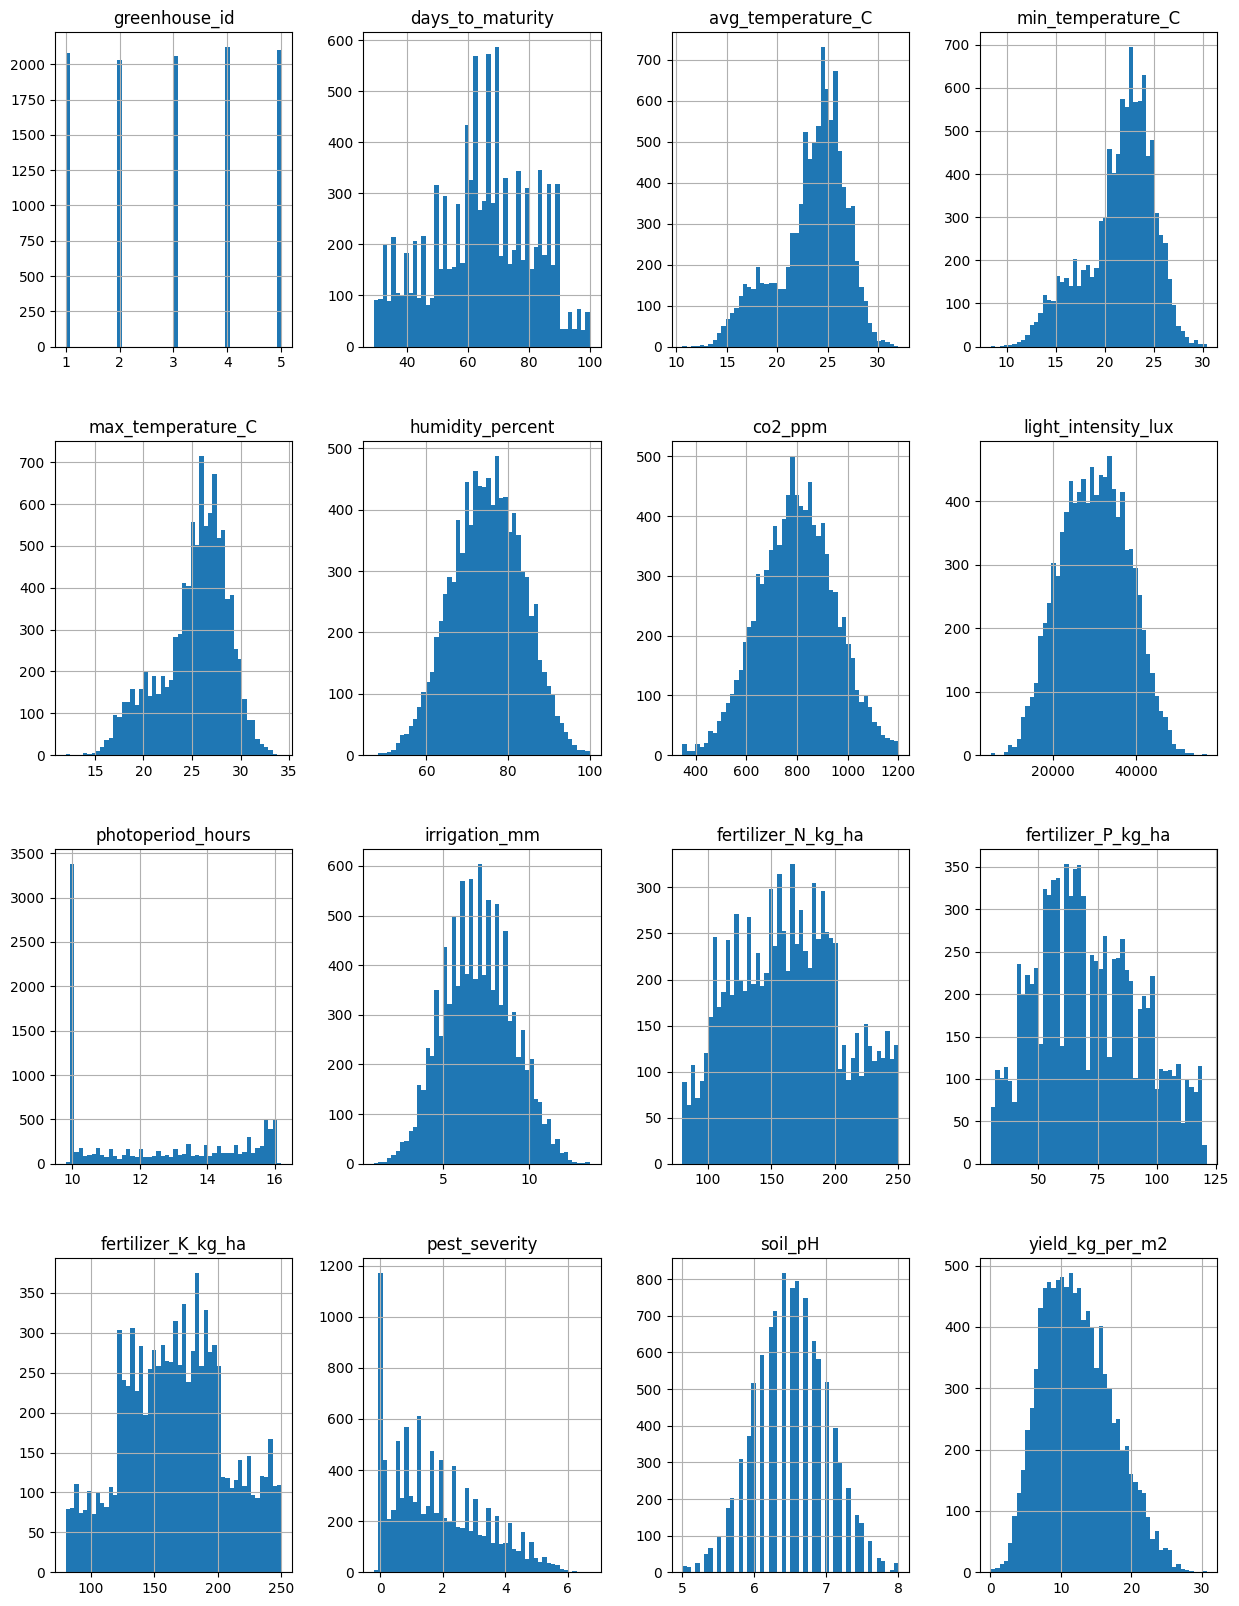

In [ ]:
df.hist(bins=50, figsize=(15, 20))

# Data Wrangling

In [ ]:
df.head()

,greenhouse_id,crop_type,variety,planting_date,harvest_date,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,fertilizer_N_kg_ha,fertilizer_P_kg_ha,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2
0,1.0,Tomato,Beefsteak,2023-11-02,2024-01-08,67.0,27.6,25.8,30.6,73.6,917.0,16821.0,10.0,9.8,167.0,74.0,154.0,1.3,6.1,9.19
1,3.0,Cucumber,English,2023-11-01,2024-01-03,63.0,24.4,21.0,27.3,80.8,782.0,27483.0,10.0,9.2,174.0,82.0,126.0,3.2,6.3,7.42
2,5.0,Tomato,Beefsteak,2023-02-02,2023-04-19,76.0,23.9,20.6,26.0,76.6,821.0,30516.0,10.0,7.0,234.0,64.0,243.0,1.2,6.0,20.86
3,5.0,Tomato,Heirloom,2023-07-29,2023-10-21,84.0,26.7,25.5,29.6,76.1,710.0,43580.0,15.1,5.4,167.0,63.0,234.0,0.8,6.0,22.09
4,4.0,Cucumber,Slicing,2023-02-07,2023-04-15,67.0,24.1,22.4,26.5,69.8,921.0,22283.0,10.0,8.4,102.0,98.0,173.0,1.1,7.4,6.42


In [ ]:
df['planting_date'] = pd.to_datetime(df['planting_date'])
df['harvest_date'] = pd.to_datetime(df['harvest_date'])

df['planting_date_day'] = df['planting_date'].dt.day
df['planting_date_month'] = df['planting_date'].dt.month
df['planting_date_year'] = df['planting_date'].dt.year 

df['harvest_date_day'] = df['harvest_date'].dt.day
df['harvest_date_month'] = df['harvest_date'].dt.month
df['harvest_date_year'] = df['harvest_date'].dt.year

In [ ]:
df = df.drop(columns=['planting_date', 'harvest_date'])

# Split train-test

In [ ]:
train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

In [ ]:
train_set.to_csv('/Users/admin/Documents/ML Engineer/ML Project/ML Project with AI/regression_1/data/train_set.csv')
test_set.to_csv('/Users/admin/Documents/ML Engineer/ML Project/ML Project with AI/regression_1/data/test_set.csv')

In [ ]:
train_set = pd.read_csv('/Users/admin/Documents/ML Engineer/ML Project/ML Project with AI/regression_1/data/train_set.csv')
train_set.head()

,Unnamed: 0,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
0,561,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,...,175.0,1.6,5.9,12.42,19,3,2023,6,6,2023
1,1162,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,...,208.0,4.0,6.2,20.27,15,5,2023,28,7,2023
2,9573,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,...,146.0,0.5,6.2,11.51,14,3,2023,3,5,2023
3,9045,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,...,221.0,2.6,7.1,13.24,1,3,2023,19,5,2023
4,3209,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,...,NaN,2.9,5.8,9.56,25,4,2023,29,6,2023


In [ ]:
train_set = train_set.drop('Unnamed: 0', axis=1)
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
0,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,...,175.0,1.6,5.9,12.42,19,3,2023,6,6,2023
1,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,...,208.0,4.0,6.2,20.27,15,5,2023,28,7,2023
2,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,...,146.0,0.5,6.2,11.51,14,3,2023,3,5,2023
3,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,...,221.0,2.6,7.1,13.24,1,3,2023,19,5,2023
4,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,...,NaN,2.9,5.8,9.56,25,4,2023,29,6,2023


In [ ]:
train_set.describe()

,greenhouse_id,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,photoperiod_hours,irrigation_mm,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
count,8320.000000,8320.000000,7896.000000,7896.000000,7896.000000,7896.000000,7870.000000,7896.000000,8320.000000,8320.000000,...,7469.000000,8221.000000,8081.000000,8320.000000,8320.000000,8320.000000,8320.0,8320.000000,8320.000000,8320.000000
mean,3.009014,64.717668,23.454027,21.556864,25.339906,74.917427,800.230114,30030.201494,12.451755,7.007440,...,166.879636,1.830848,6.505531,12.402939,15.688582,6.557692,2023.0,15.754327,6.525721,2023.179688
std,1.414227,16.386257,3.388636,3.465412,3.442503,8.568983,148.264159,8084.598545,2.309676,1.983244,...,39.626062,1.452566,0.497161,4.979355,8.833381,3.440255,0.0,8.833665,3.439699,0.383950
min,1.000000,29.000000,10.600000,8.400000,12.000000,47.200000,348.000000,5000.000000,9.800000,1.200000,...,80.000000,-0.200000,5.000000,0.100000,1.000000,1.000000,2023.0,1.000000,1.000000,2023.000000
25%,2.000000,53.000000,21.800000,19.800000,23.500000,68.900000,699.000000,24039.750000,10.000000,5.600000,...,137.000000,0.600000,6.200000,8.550000,8.000000,4.000000,2023.0,8.000000,4.000000,2023.000000
50%,3.000000,65.000000,24.100000,22.200000,26.000000,75.000000,800.000000,30107.500000,12.100000,7.000000,...,167.000000,1.600000,6.500000,11.950000,16.000000,7.000000,2023.0,16.000000,7.000000,2023.000000
75%,4.000000,77.000000,25.800000,24.000000,27.700000,81.025000,902.000000,36053.250000,14.800000,8.400000,...,194.000000,2.800000,6.800000,15.740000,23.000000,10.000000,2023.0,23.000000,10.000000,2023.000000
max,5.000000,100.000000,32.000000,30.400000,34.200000,100.000000,1200.000000,56075.000000,16.200000,13.500000,...,250.000000,6.700000,8.000000,30.640000,31.000000,12.000000,2023.0,31.000000,12.000000,2024.000000


array([[<Axes: title={'center': 'greenhouse_id'}>,
        <Axes: title={'center': 'days_to_maturity'}>,
        <Axes: title={'center': 'avg_temperature_C'}>,
        <Axes: title={'center': 'min_temperature_C'}>,
        <Axes: title={'center': 'max_temperature_C'}>],
       [<Axes: title={'center': 'humidity_percent'}>,
        <Axes: title={'center': 'co2_ppm'}>,
        <Axes: title={'center': 'light_intensity_lux'}>,
        <Axes: title={'center': 'photoperiod_hours'}>,
        <Axes: title={'center': 'irrigation_mm'}>],
       [<Axes: title={'center': 'fertilizer_N_kg_ha'}>,
        <Axes: title={'center': 'fertilizer_P_kg_ha'}>,
        <Axes: title={'center': 'fertilizer_K_kg_ha'}>,
        <Axes: title={'center': 'pest_severity'}>,
        <Axes: title={'center': 'soil_pH'}>],
       [<Axes: title={'center': 'yield_kg_per_m2'}>,
        <Axes: title={'center': 'planting_date_day'}>,
        <Axes: title={'center': 'planting_date_month'}>,
        <Axes: title={'center': 'pla

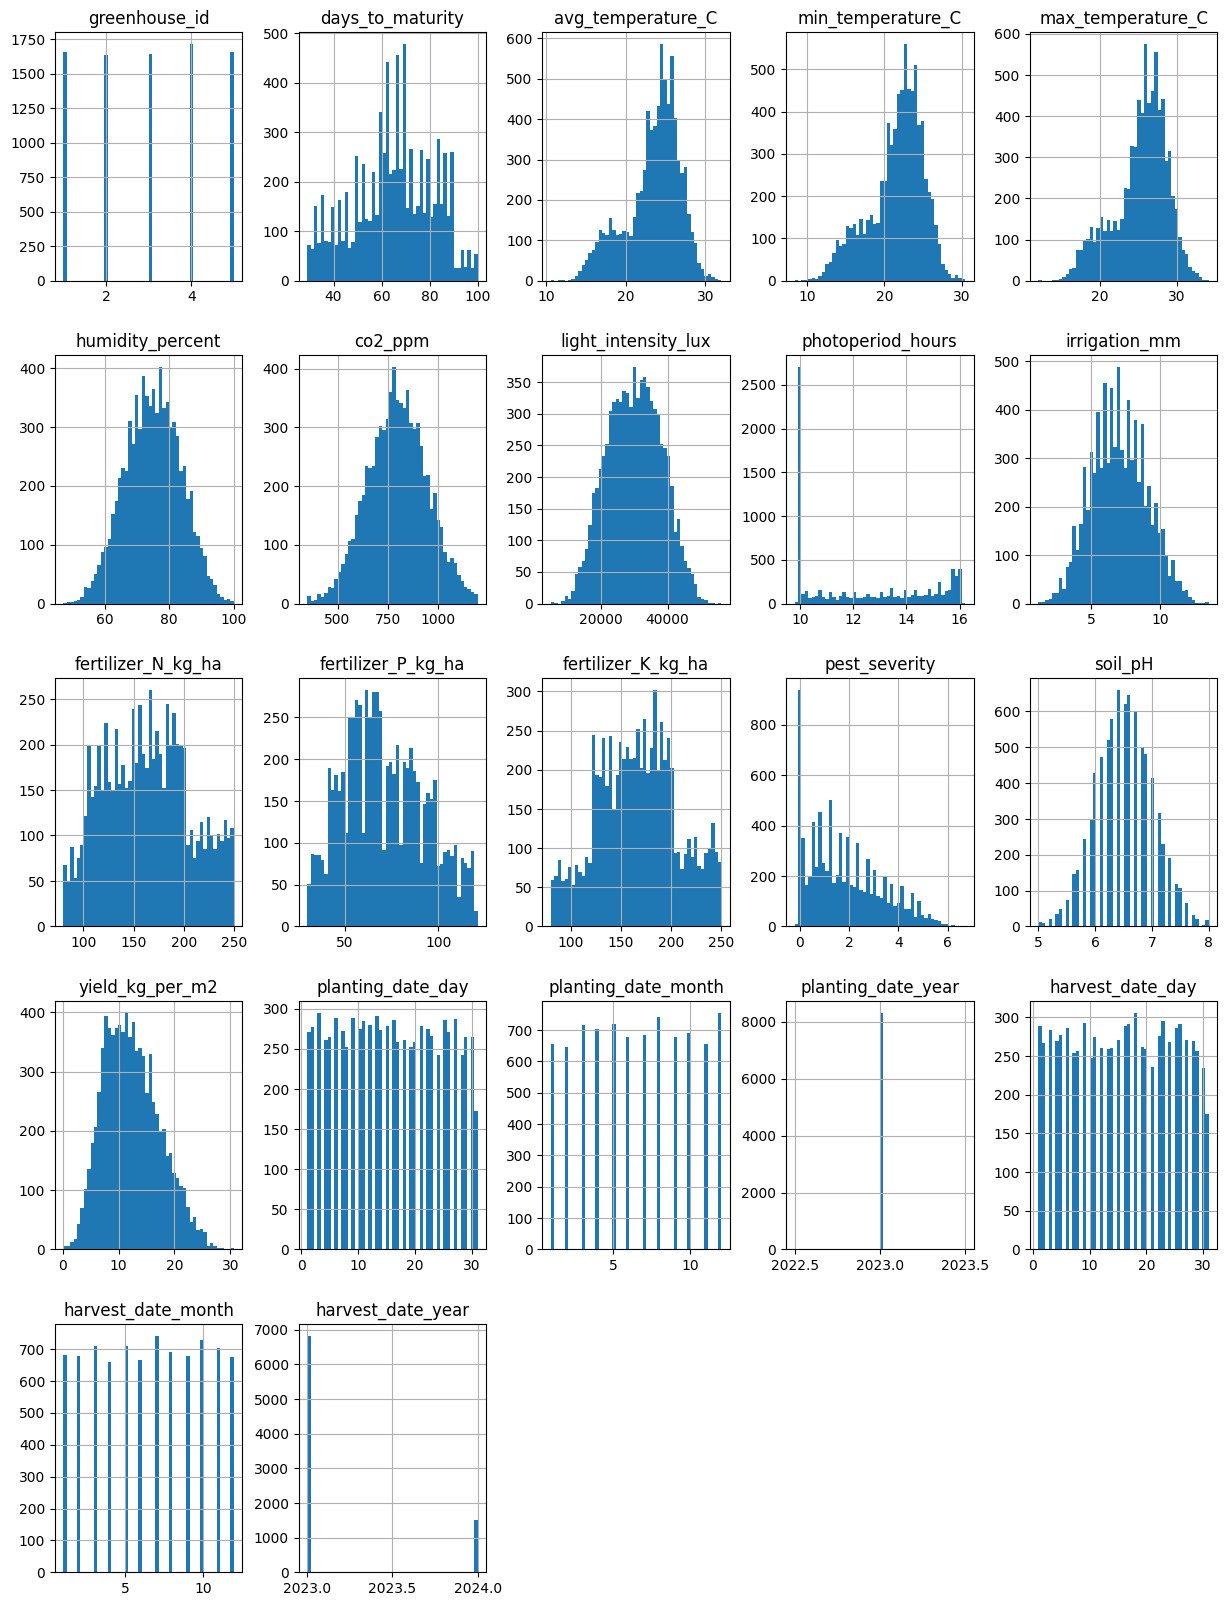

In [ ]:
train_set.hist(bins=50, figsize=(15,20))

# EDA for Train Set

## Univariate EDA

In [ ]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8320 entries, 0 to 8319
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        8320 non-null   float64
 1   crop_type            8320 non-null   object 
 2   variety              8320 non-null   object 
 3   days_to_maturity     8320 non-null   float64
 4   avg_temperature_C    7896 non-null   float64
 5   min_temperature_C    7896 non-null   float64
 6   max_temperature_C    7896 non-null   float64
 7   humidity_percent     7896 non-null   float64
 8   co2_ppm              7870 non-null   float64
 9   light_intensity_lux  7896 non-null   float64
 10  photoperiod_hours    8320 non-null   float64
 11  irrigation_mm        8320 non-null   float64
 12  fertilizer_N_kg_ha   7469 non-null   float64
 13  fertilizer_P_kg_ha   7469 non-null   float64
 14  fertilizer_K_kg_ha   7469 non-null   float64
 15  pest_severity        8221 non-null   f

In [ ]:
train_set.head()

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
0,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,...,175.0,1.6,5.9,12.42,19,3,2023,6,6,2023
1,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,...,208.0,4.0,6.2,20.27,15,5,2023,28,7,2023
2,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,...,146.0,0.5,6.2,11.51,14,3,2023,3,5,2023
3,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,...,221.0,2.6,7.1,13.24,1,3,2023,19,5,2023
4,5.0,Cucumber,Pickling,65.0,24.5,22.5,26.6,91.3,739.0,31260.0,...,NaN,2.9,5.8,9.56,25,4,2023,29,6,2023


In [ ]:
cols_to_exclude = ['planting_date_day', 'planting_date_month', 'planting_date_year', 'harvest_date_day', 'harvest_date_month', 'harvest_date_year']

num_data = train_set.select_dtypes(include=['number']).columns
cat_data = train_set.select_dtypes(include=['object']).columns

num_data = num_data.drop(cols_to_exclude)

### Numerical

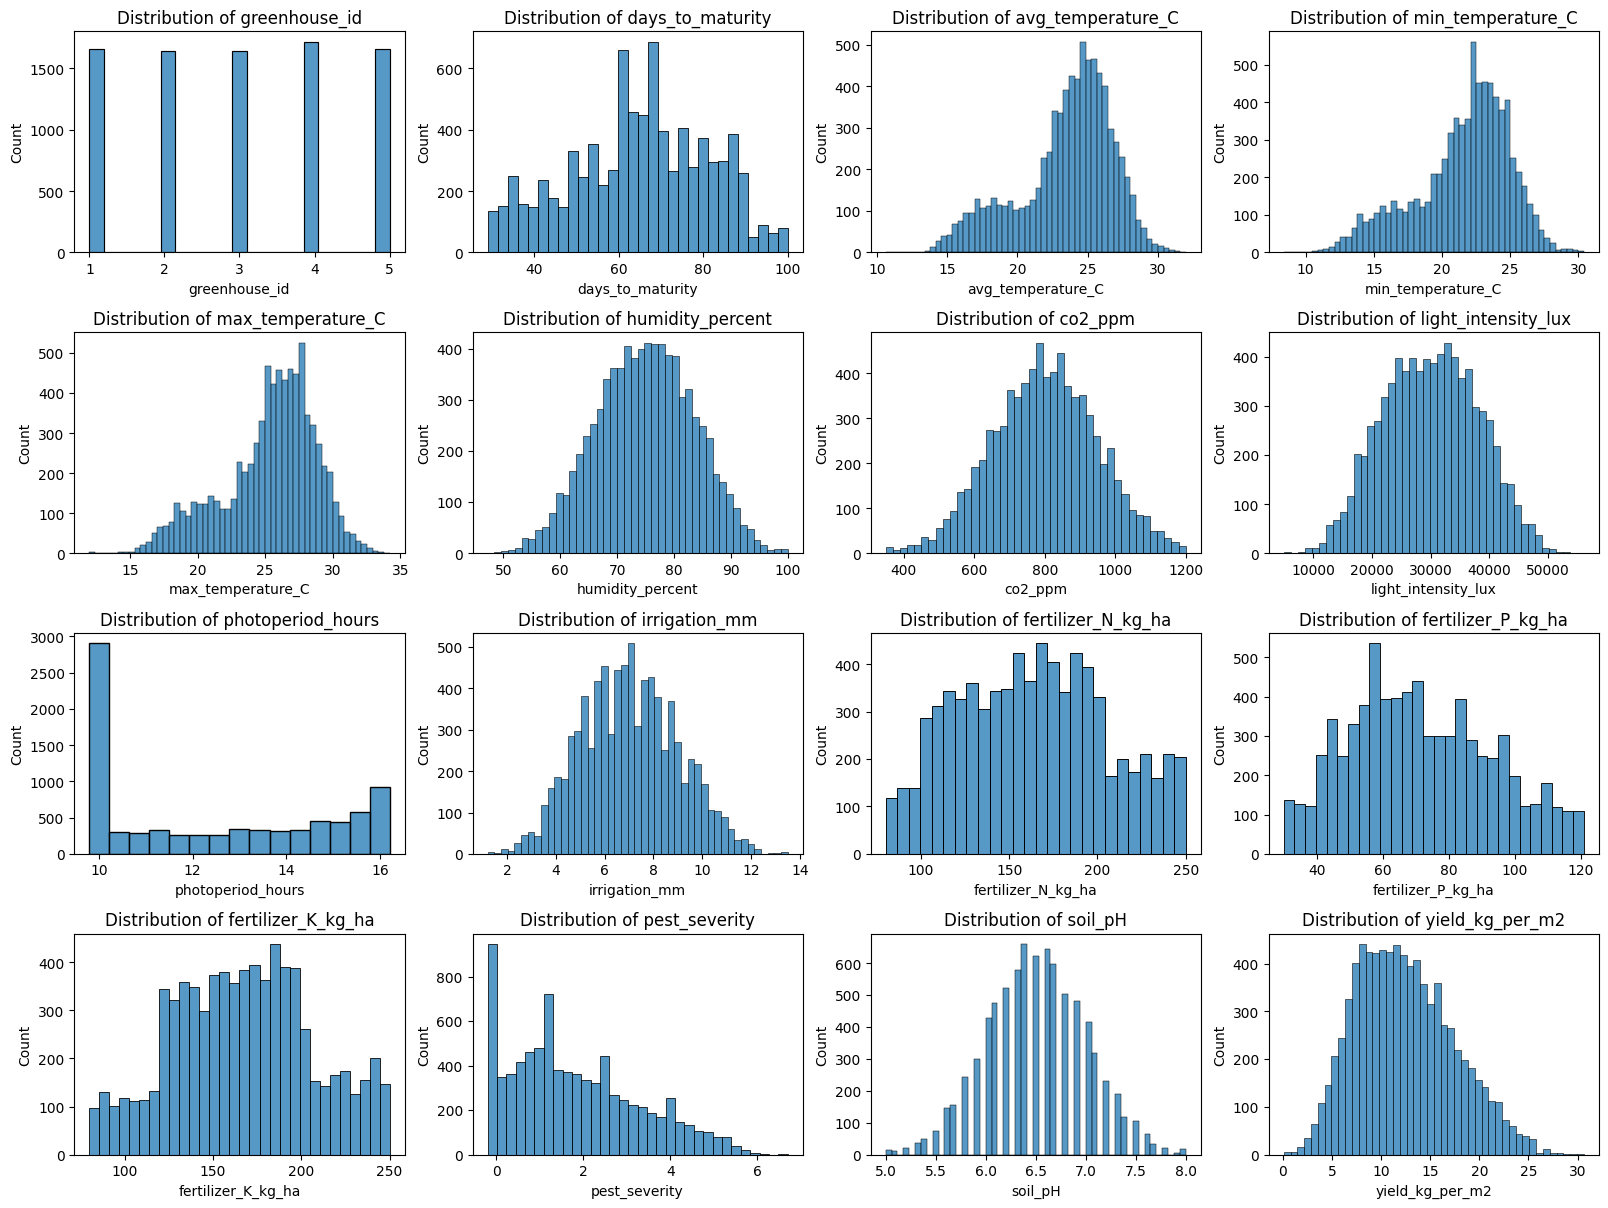

In [ ]:
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(16,12))
axs = axs.flatten() # mengubah array multi-dimensi menjadi 1 dimensi. axs awal -> array 2D (4 baris × 4 kolom) axs[0][0], axs[0][1], ..., axs[3][3], setelah di flatten -> axs[0], axs[1], ..., axs[15]

for i, column in enumerate(num_data):
    sns.histplot(train_set[column], ax=axs[i])
    axs[i].set_title(f'Distribution of {column}')

plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
plt.show()

### Categorical

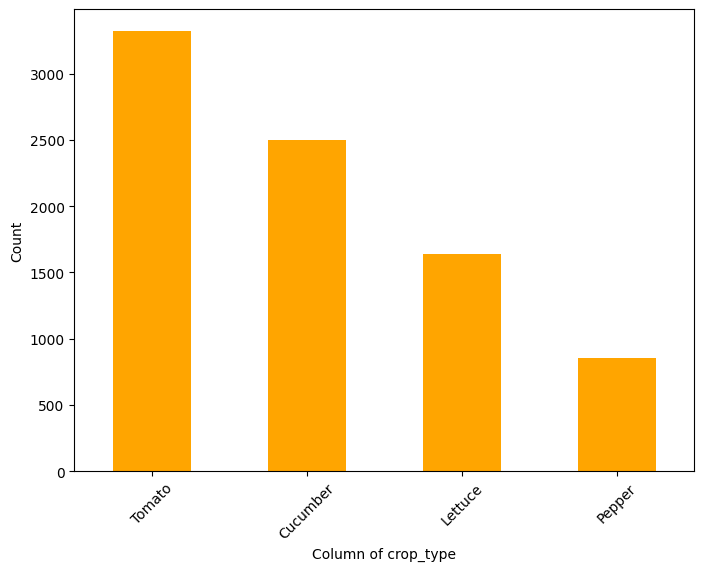

In [ ]:
def uni_cat(column_name, color):
    cat_count = train_set[column_name].value_counts()

    plt.figure(figsize=(8,6))
    cat_count.plot(kind='bar', color=color)

    plt.xlabel(f'Column of {column_name}')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()


uni_cat('crop_type', 'orange')

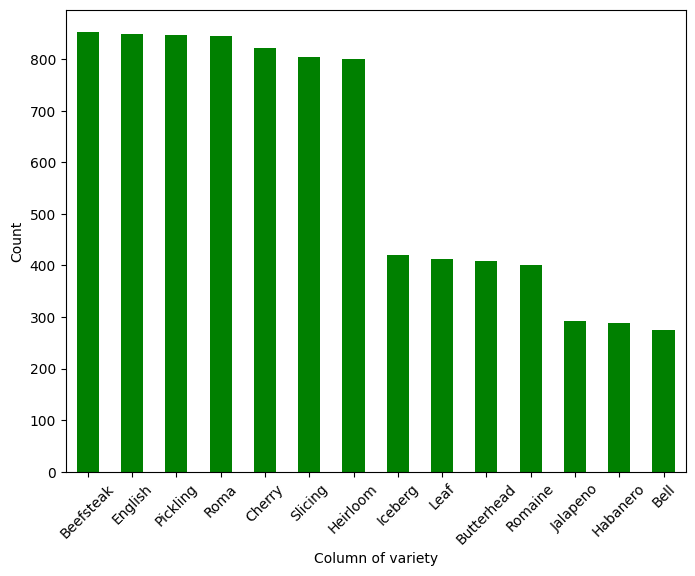

In [ ]:
uni_cat('variety', 'green')

## Bivariate EDA

In [ ]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8320 entries, 0 to 8319
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        8320 non-null   float64
 1   crop_type            8320 non-null   object 
 2   variety              8320 non-null   object 
 3   days_to_maturity     8320 non-null   float64
 4   avg_temperature_C    7896 non-null   float64
 5   min_temperature_C    7896 non-null   float64
 6   max_temperature_C    7896 non-null   float64
 7   humidity_percent     7896 non-null   float64
 8   co2_ppm              7870 non-null   float64
 9   light_intensity_lux  7896 non-null   float64
 10  photoperiod_hours    8320 non-null   float64
 11  irrigation_mm        8320 non-null   float64
 12  fertilizer_N_kg_ha   7469 non-null   float64
 13  fertilizer_P_kg_ha   7469 non-null   float64
 14  fertilizer_K_kg_ha   7469 non-null   float64
 15  pest_severity        8221 non-null   f

<Figure size 800x600 with 0 Axes>

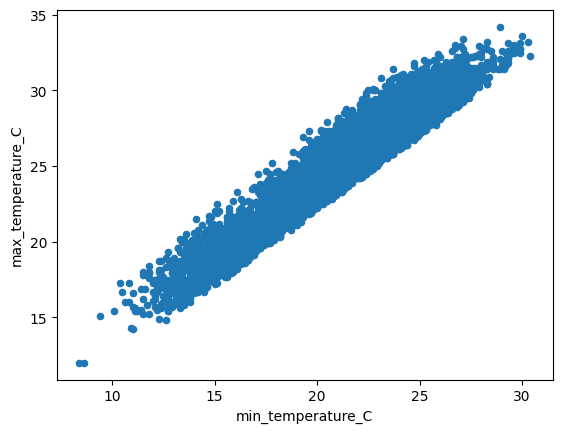

In [ ]:
### Numerical vs Numerical 

def plot_num_vs_num(col_1, col_2):
    plt.figure(figsize=(8,6))
    train_set.plot(kind='scatter', x=col_1, y=col_2)
    plt.show()

plot_num_vs_num("min_temperature_C", "max_temperature_C")

<Figure size 800x600 with 0 Axes>

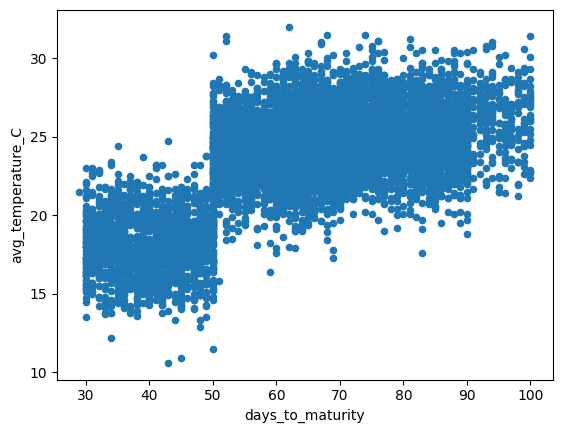

In [ ]:
plot_num_vs_num("days_to_maturity", "avg_temperature_C")

<Figure size 800x600 with 0 Axes>

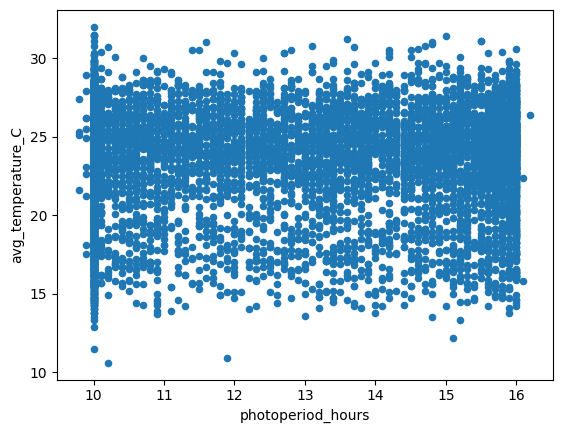

In [ ]:
plot_num_vs_num("photoperiod_hours", "avg_temperature_C")

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5]),
 [Text(0.5, 0, 'greenhouse_id'),
  Text(1.5, 0, 'days_to_maturity'),
  Text(2.5, 0, 'avg_temperature_C'),
  Text(3.5, 0, 'min_temperature_C'),
  Text(4.5, 0, 'max_temperature_C'),
  Text(5.5, 0, 'humidity_percent'),
  Text(6.5, 0, 'co2_ppm'),
  Text(7.5, 0, 'light_intensity_lux'),
  Text(8.5, 0, 'photoperiod_hours'),
  Text(9.5, 0, 'irrigation_mm'),
  Text(10.5, 0, 'fertilizer_N_kg_ha'),
  Text(11.5, 0, 'fertilizer_P_kg_ha'),
  Text(12.5, 0, 'fertilizer_K_kg_ha'),
  Text(13.5, 0, 'pest_severity'),
  Text(14.5, 0, 'soil_pH'),
  Text(15.5, 0, 'yield_kg_per_m2')])

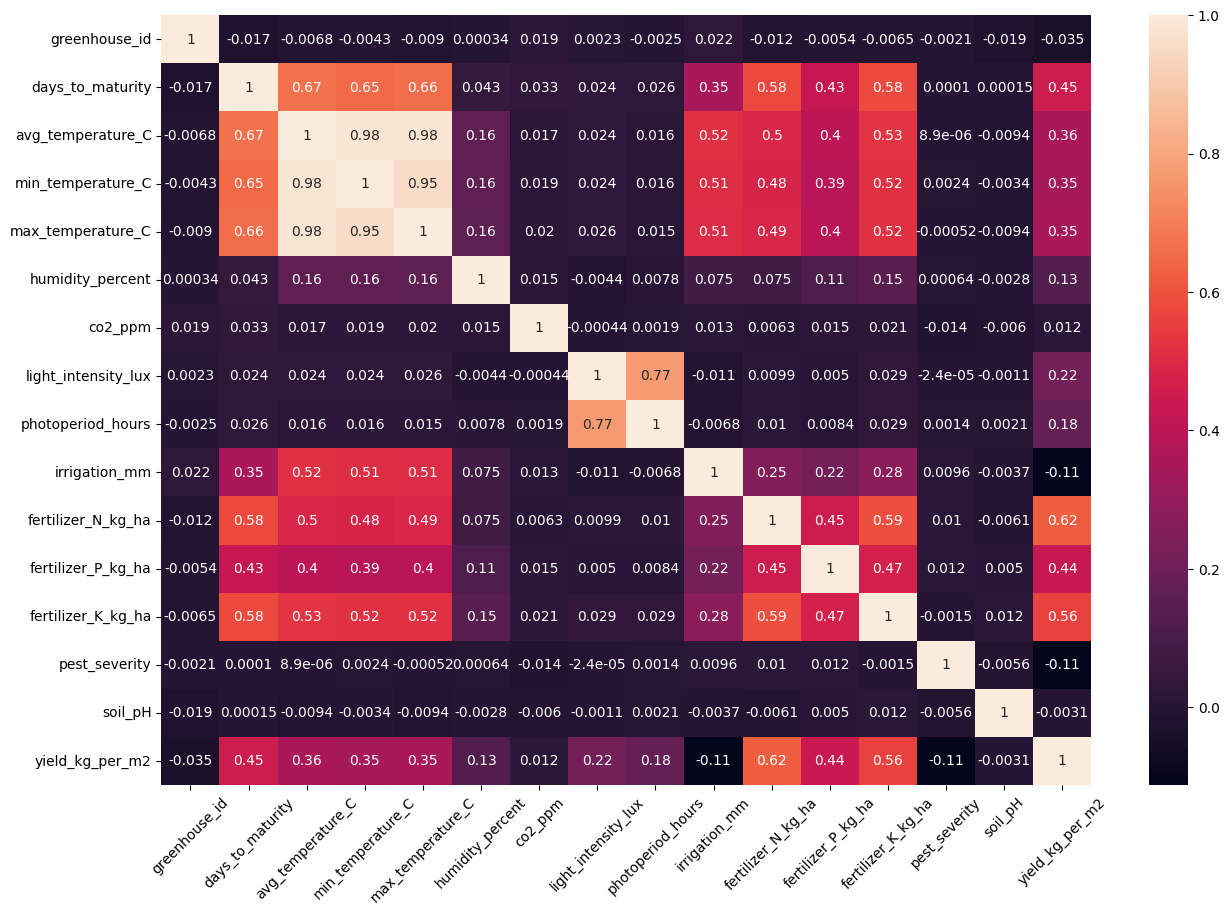

In [ ]:
plt.figure(figsize=(15, 10))
sns.heatmap(train_set[num_data].corr(), annot=True)
plt.xticks(rotation=45)

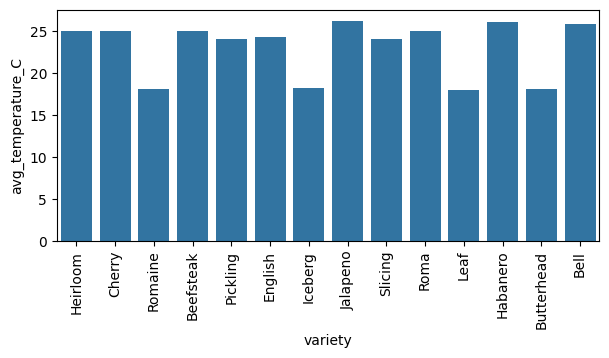

In [ ]:
### Numerical vs Categorical 

def num_vs_cat(col_1, col_2):
    plt.figure(figsize=(7, 3))
    sns.barplot(data=train_set, x=col_1, y=col_2, errorbar=None)
    plt.xticks(rotation=90)
    plt.show()

num_vs_cat("variety", "avg_temperature_C")

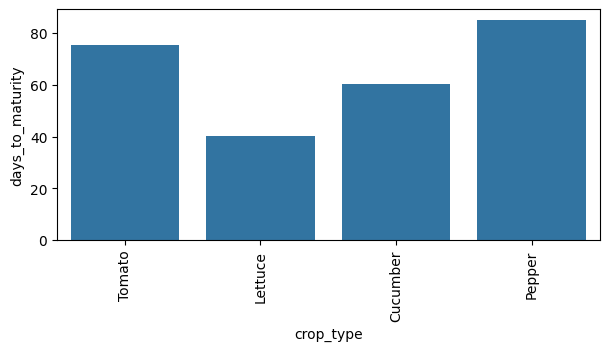

In [ ]:
num_vs_cat("crop_type", "days_to_maturity")

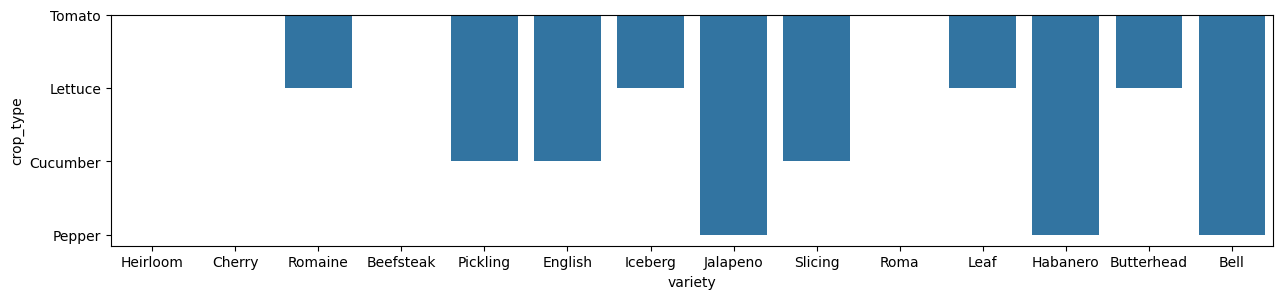

In [ ]:
### Categorical vs Categorical 

plt.figure(figsize=(15, 3))
sns.barplot(data=train_set, x='variety', y='crop_type', errorbar=None)
plt.show()

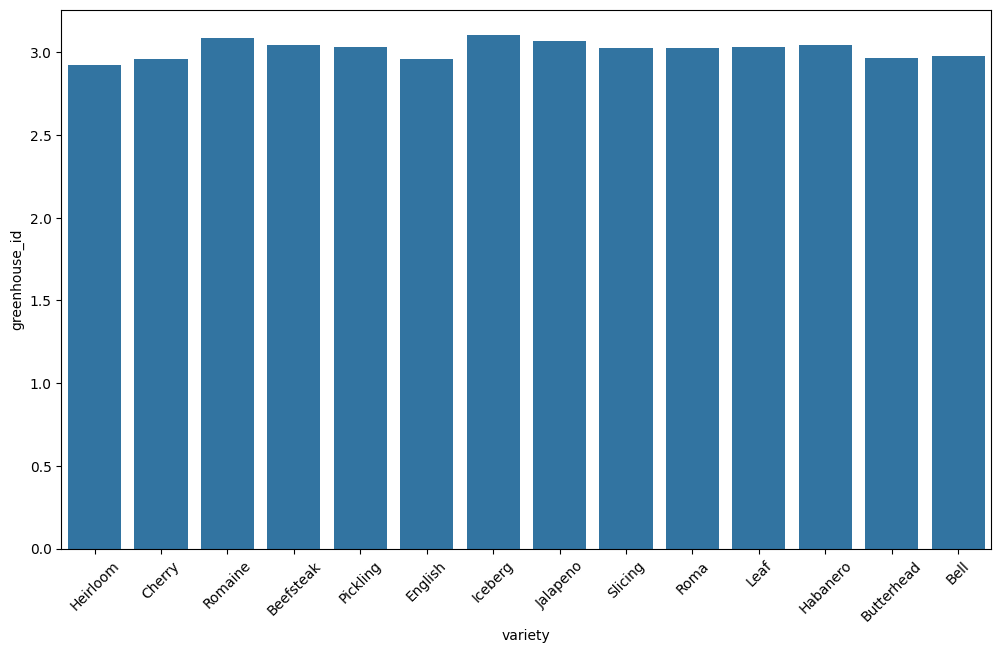

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(data=train_set, x='variety', y='greenhouse_id', errorbar=None)
plt.xticks(rotation=45)
plt.show()

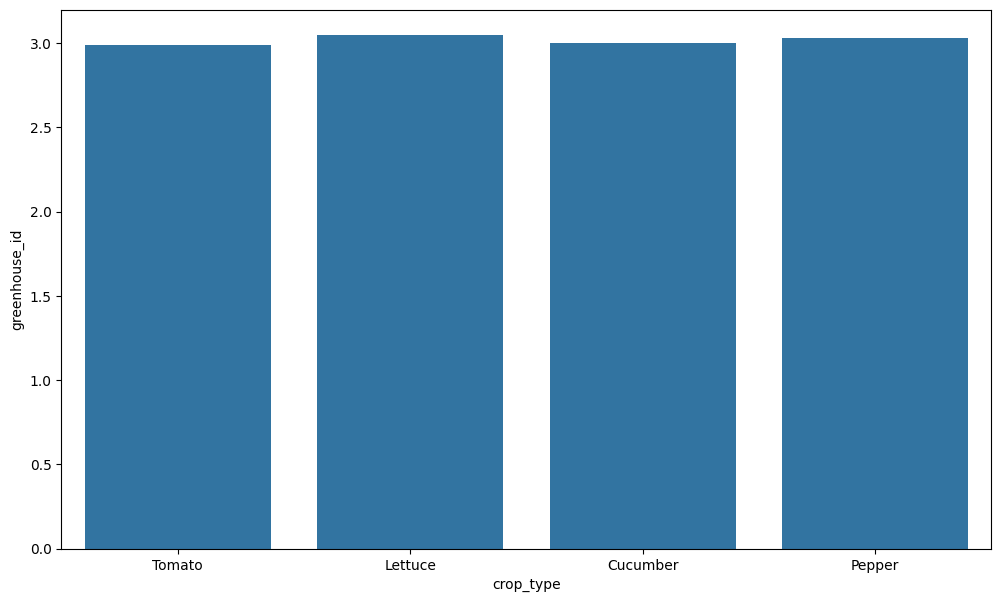

In [ ]:
plt.figure(figsize=(12, 7))
sns.barplot(data=train_set, x='crop_type', y='greenhouse_id', errorbar=None)
plt.show()

## Multivariate EDA

In [ ]:
fig = px.scatter(train_set, x='days_to_maturity', y='avg_temperature_C', color='crop_type')
fig.show()

# Data Cleaning

In [ ]:
train_set['greenhouse_id'].value_counts()

greenhouse_id
4.0    1716
1.0    1661
5.0    1660
3.0    1644
2.0    1639
Name: count, dtype: int64

### Missing Value

In [ ]:
missing_values = train_set.isnull().sum()
percentage_missing = round((missing_values / len(train_set)) * 100, 3)

missing_data_info = pd.DataFrame({
    'missing_value': missing_values,
    'percentage_missing': percentage_missing
})

missing_data_info

,missing_value,percentage_missing
greenhouse_id,0,0.000
crop_type,0,0.000
variety,0,0.000
days_to_maturity,0,0.000
avg_temperature_C,424,5.096
min_temperature_C,424,5.096
max_temperature_C,424,5.096
humidity_percent,424,5.096
co2_ppm,450,5.409
light_intensity_lux,424,5.096


### Duplicated Values

In [ ]:
train_set.duplicated().any()

True

In [ ]:
train_set[train_set.duplicated()]

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
1358,4.0,Tomato,Cherry,85.0,26.6,25.4,28.0,73.8,815.0,42926.0,...,184.0,0.4,6.0,25.78,31,7,2023,24,10,2023
1438,2.0,Tomato,Heirloom,64.0,25.4,23.9,26.5,74.7,790.0,16158.0,...,215.0,2.8,6.3,14.27,17,12,2023,19,2,2024
1456,4.0,Cucumber,English,54.0,24.0,22.4,25.4,86.3,789.0,28073.0,...,168.0,2.3,6.7,13.82,10,5,2023,3,7,2023
1771,2.0,Cucumber,Pickling,52.0,25.8,22.6,27.1,85.8,927.0,12000.0,...,124.0,2.1,5.4,9.38,13,2,2023,6,4,2023
1965,1.0,Tomato,Cherry,89.0,24.4,22.3,25.6,62.9,899.0,41093.0,...,156.0,1.7,6.3,21.81,30,5,2023,27,8,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8233,2.0,Pepper,Habanero,78.0,26.1,24.7,27.3,70.8,636.0,23065.0,...,187.0,0.9,6.2,13.84,11,2,2023,30,4,2023
8286,5.0,Cucumber,Pickling,55.0,23.6,22.3,25.2,78.2,720.0,31726.0,...,198.0,0.0,6.9,12.68,3,5,2023,27,6,2023
8295,5.0,Cucumber,English,50.0,22.7,21.0,24.7,77.0,868.0,36903.0,...,NaN,1.8,6.8,11.55,8,9,2023,28,10,2023
8303,1.0,Lettuce,Romaine,48.0,20.5,18.6,22.5,75.5,1040.0,17085.0,...,88.0,0.0,7.5,6.75,21,1,2023,10,3,2023


In [ ]:
# Mencari tau baris apa mana yang nilainya duplikat
dup = train_set[train_set.duplicated(keep=False)]
dup_sorted = dup.sort_values(by=list(train_set.columns))
dup_sorted

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
3386,1.0,Cucumber,English,65.0,25.1,23.9,26.2,85.7,631.0,24954.0,...,149.0,2.4,7.3,8.12,13,3,2023,17,5,2023
7616,1.0,Cucumber,English,65.0,25.1,23.9,26.2,85.7,631.0,24954.0,...,149.0,2.4,7.3,8.12,13,3,2023,17,5,2023
126,1.0,Cucumber,English,67.0,24.2,22.2,26.1,71.9,551.0,23552.0,...,137.0,1.6,7.4,10.93,20,10,2023,26,12,2023
4568,1.0,Cucumber,English,67.0,24.2,22.2,26.1,71.9,551.0,23552.0,...,137.0,1.6,7.4,10.93,20,10,2023,26,12,2023
2661,1.0,Cucumber,Pickling,65.0,NaN,NaN,NaN,NaN,NaN,NaN,...,196.0,4.3,6.1,7.87,8,6,2023,12,8,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7950,5.0,Tomato,Roma,79.0,NaN,NaN,NaN,NaN,NaN,NaN,...,210.0,0.0,6.6,16.89,6,2,2023,26,4,2023
3031,5.0,Tomato,Roma,83.0,25.2,22.7,27.8,65.8,886.0,32629.0,...,212.0,4.5,5.1,13.40,9,5,2023,31,7,2023
5641,5.0,Tomato,Roma,83.0,25.2,22.7,27.8,65.8,886.0,32629.0,...,212.0,4.5,5.1,13.40,9,5,2023,31,7,2023
284,5.0,Tomato,Roma,86.0,24.4,21.4,25.5,84.1,718.0,22857.0,...,216.0,0.7,5.8,14.09,12,12,2023,7,3,2024


In [ ]:
# Mencari tau pasangan baris yang termasuk duplikat
dup_groups = train_set[train_set.duplicated(keep=False)].groupby(list(train_set.columns))

for name, group in dup_groups:
    print('---Duplicate Group---')
    print(group)

---Duplicate Group---
      greenhouse_id crop_type  variety  days_to_maturity  avg_temperature_C  \
3386            1.0  Cucumber  English              65.0               25.1   
7616            1.0  Cucumber  English              65.0               25.1   

      min_temperature_C  max_temperature_C  humidity_percent  co2_ppm  \
3386               23.9               26.2              85.7    631.0   
7616               23.9               26.2              85.7    631.0   

      light_intensity_lux  ...  fertilizer_K_kg_ha  pest_severity  soil_pH  \
3386              24954.0  ...               149.0            2.4      7.3   
7616              24954.0  ...               149.0            2.4      7.3   

      yield_kg_per_m2  planting_date_day  planting_date_month  \
3386             8.12                 13                    3   
7616             8.12                 13                    3   

      planting_date_year  harvest_date_day  harvest_date_month  \
3386                202

In [ ]:
# Membuangan data duplikat 

train_set = train_set.drop_duplicates()

### Handle Outliers

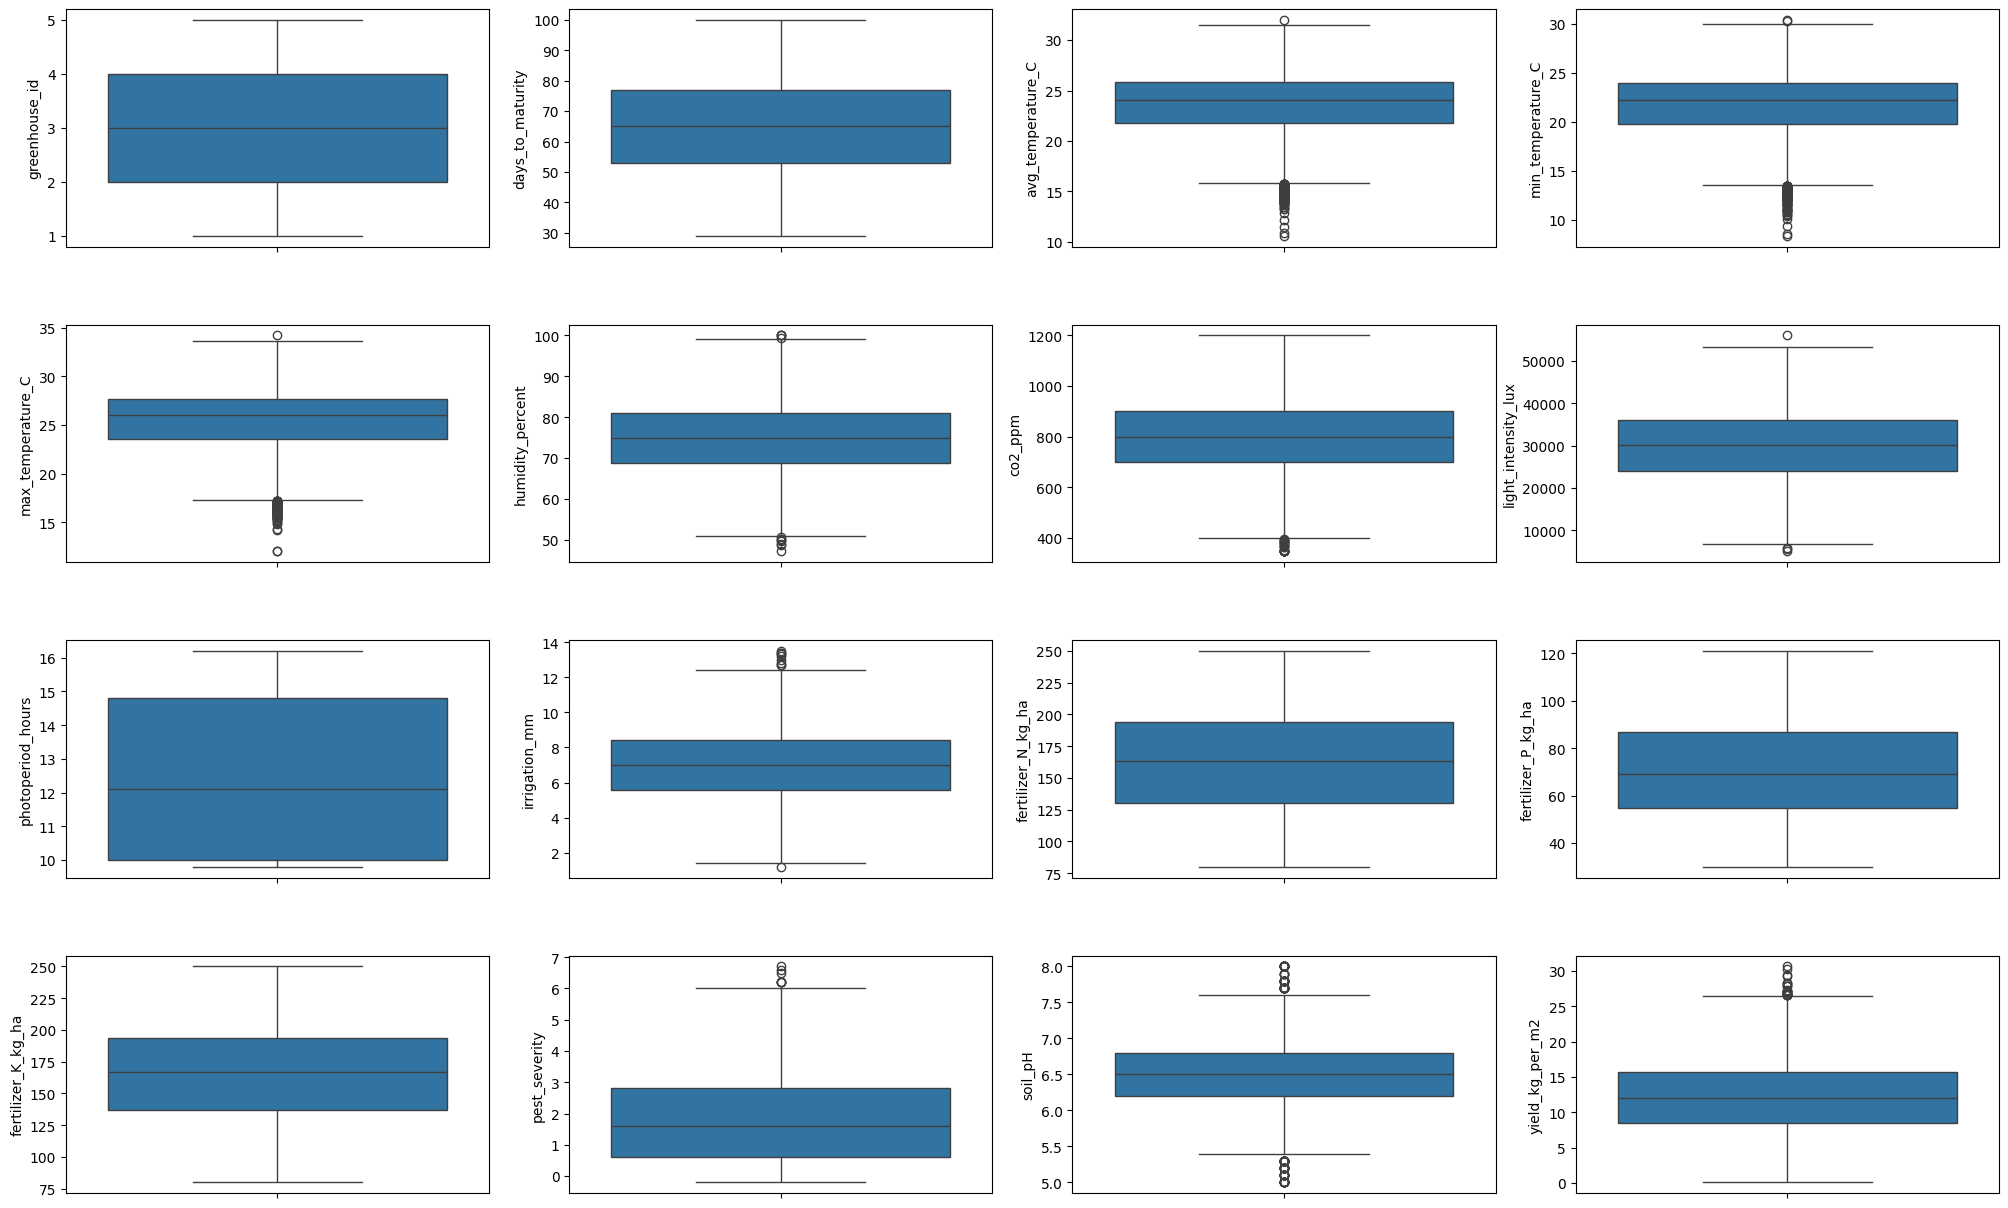

In [ ]:
def vis_outliers(data):
    fig, axs = plt.subplots(ncols=4, nrows=4, figsize=(20, 12))
    axs = axs.flatten()

    for i, column in enumerate(data):
        sns.boxplot(y=data[column], data=data, ax=axs[i], whis=1.5)
    
    plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.)
    plt.show()

vis_outliers(train_set[num_data])


In [ ]:
# Find and count outlier
outlier_mask = pd.Series(False, index=train_set.index)

for col in num_data:
    Q1 = train_set[col].quantile(0.25)
    Q3 = train_set[col].quantile(0.75)

    IQR = Q3 - Q1 

    lower = Q1 - 1.5 * IQR 
    upper = Q3 + 1.5 * IQR 

    mask = (train_set[col] < lower) | (train_set[col] > upper)
    outlier_mask = outlier_mask | mask 

outlier_rows = train_set[outlier_mask]
outlier_rows

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
6,4.0,Lettuce,Iceberg,41.0,15.1,13.6,17.1,72.0,568.0,31844.0,...,102.0,2.5,6.6,8.18,1,9,2023,12,10,2023
27,3.0,Lettuce,Leaf,42.0,14.9,13.6,16.9,61.9,613.0,23469.0,...,143.0,0.6,6.5,4.66,23,9,2023,4,11,2023
41,2.0,Lettuce,Leaf,50.0,15.4,13.5,17.4,58.7,872.0,16789.0,...,91.0,0.8,6.6,5.90,29,10,2023,18,12,2023
48,1.0,Lettuce,Butterhead,31.0,15.7,13.8,18.9,66.2,805.0,15131.0,...,106.0,0.3,7.4,5.50,25,11,2023,26,12,2023
59,4.0,Tomato,Beefsteak,61.0,26.3,25.0,27.4,75.3,963.0,29253.0,...,192.0,1.5,6.2,13.95,6,2,2023,8,4,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8247,2.0,Lettuce,Iceberg,43.0,18.7,16.5,20.4,64.6,710.0,32794.0,...,91.0,1.1,5.3,6.35,25,4,2023,7,6,2023
8251,3.0,Cucumber,Pickling,50.0,23.2,22.1,24.8,85.0,882.0,35229.0,...,158.0,0.8,7.7,12.65,5,8,2023,24,9,2023
8270,3.0,Lettuce,Romaine,37.0,14.0,12.8,15.8,85.3,827.0,28385.0,...,105.0,1.6,6.8,7.81,16,9,2023,23,10,2023
8300,3.0,Tomato,Cherry,82.0,27.8,24.6,30.6,90.3,887.0,40688.0,...,185.0,1.2,5.2,13.37,11,6,2023,1,9,2023


In [ ]:
# Drop outliers
mask = pd.Series(True, index=train_set.index)

for col in num_data:
    Q1 = train_set[col].quantile(0.25)
    Q3 = train_set[col].quantile(0.75)

    IQR = Q3 - Q1 

    lower = Q1 - 1.5 * IQR 
    upper = Q3 + 1.5 * IQR 

    mask &= (train_set[col] >= lower) & (train_set[col] <= upper)

train_set = train_set[mask]
train_set

,greenhouse_id,crop_type,variety,days_to_maturity,avg_temperature_C,min_temperature_C,max_temperature_C,humidity_percent,co2_ppm,light_intensity_lux,...,fertilizer_K_kg_ha,pest_severity,soil_pH,yield_kg_per_m2,planting_date_day,planting_date_month,planting_date_year,harvest_date_day,harvest_date_month,harvest_date_year
0,5.0,Tomato,Heirloom,79.0,24.3,23.1,25.6,82.5,1053.0,25609.0,...,175.0,1.6,5.9,12.42,19,3,2023,6,6,2023
1,1.0,Tomato,Cherry,74.0,21.2,19.7,23.4,80.7,775.0,39803.0,...,208.0,4.0,6.2,20.27,15,5,2023,28,7,2023
2,3.0,Lettuce,Romaine,50.0,18.6,15.8,21.0,76.0,726.0,30218.0,...,146.0,0.5,6.2,11.51,14,3,2023,3,5,2023
3,5.0,Tomato,Beefsteak,79.0,27.7,25.8,29.2,80.6,1050.0,31051.0,...,221.0,2.6,7.1,13.24,1,3,2023,19,5,2023
5,4.0,Cucumber,English,64.0,23.1,20.9,25.3,71.3,727.0,41380.0,...,126.0,1.4,6.3,17.89,16,6,2023,19,8,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8315,3.0,Cucumber,Slicing,69.0,27.0,25.3,28.2,77.9,551.0,37738.0,...,135.0,2.2,6.0,17.16,19,8,2023,27,10,2023
8316,5.0,Tomato,Beefsteak,66.0,26.7,24.7,27.8,82.4,960.0,37206.0,...,230.0,0.0,6.5,17.43,7,7,2023,11,9,2023
8317,4.0,Tomato,Beefsteak,79.0,22.9,19.7,26.3,77.0,908.0,25080.0,...,151.0,1.3,6.5,16.79,5,5,2023,23,7,2023
8318,3.0,Cucumber,English,70.0,25.7,24.5,27.5,85.4,750.0,38914.0,...,155.0,3.6,6.3,14.07,22,5,2023,31,7,2023


### Data Type Correction 

In [ ]:
train_set['greenhouse_id'] = train_set['greenhouse_id'].astype('object')

In [ ]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6279 entries, 0 to 8319
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   greenhouse_id        6279 non-null   object 
 1   crop_type            6279 non-null   object 
 2   variety              6279 non-null   object 
 3   days_to_maturity     6279 non-null   float64
 4   avg_temperature_C    6279 non-null   float64
 5   min_temperature_C    6279 non-null   float64
 6   max_temperature_C    6279 non-null   float64
 7   humidity_percent     6279 non-null   float64
 8   co2_ppm              6279 non-null   float64
 9   light_intensity_lux  6279 non-null   float64
 10  photoperiod_hours    6279 non-null   float64
 11  irrigation_mm        6279 non-null   float64
 12  fertilizer_N_kg_ha   6279 non-null   float64
 13  fertilizer_P_kg_ha   6279 non-null   float64
 14  fertilizer_K_kg_ha   6279 non-null   float64
 15  pest_severity        6279 non-null   float6

# Transformation Pipelines

In [ ]:
X = train_set.drop('yield_kg_per_m2', axis=1)
y = train_set['yield_kg_per_m2']

cols_to_exclude = ['planting_date_day', 'planting_date_month', 'planting_date_year', 'harvest_date_day', 'harvest_date_month', 'harvest_date_year']

num_data = X.select_dtypes(include=['number']).columns
cat_data = X.select_dtypes(include=['object']).columns

num_data = num_data.drop(cols_to_exclude)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_data),
    ('cat', cat_pipeline, cat_data)
])

pipeline_lr = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', SelectFromModel(RandomForestRegressor(n_estimators=100, random_state=42))),
    ('model', LinearRegression())
    ])

pipeline_lr.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['days_to_maturity', 'avg_temperature_C', 'min_temperature_C',
       'max_temperature_C', 'humidity_percent', 'co2_ppm',
       'light_intensity_lux', 'photoperiod_hours', 'irrigation_mm',
       'fertilizer_N_...
       'pest_severity', 'soil_pH'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['greenhouse_id', 'crop_type', 'variety'], dtype='object'))])),
                ('feature_selection',
                 SelectFromModel(estimator=RandomForestRegressor(random_state=42))),
                ('model', LinearRegression())])

In [ ]:
y_pred_test = pipeline_lr.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print('RMSE:', rmse)

RMSE: 2.5624384238041418


In [ ]:
y_train.describe()

count    4709.000000
mean       12.543468
std         4.874800
min         0.910000
25%         8.840000
50%        12.110000
75%        15.820000
max        26.460000
Name: yield_kg_per_m2, dtype: float64

In [ ]:
""" 
RMSE: 2.52
mean: 12.68
std: 4.89
range: 0.1 - 26.46 

2.52/12.69 = 0.20(20%)
- error sekitar 20% dari rata-rata 

2.52 / 4.89 = 0.51
- RMSE -> 51% dari variasi data artinya model menangkap sekitar setnah variasi data 

Prediksi:
Actual -> 12
Pred -> 14.5 
selisih: 2.5 -> masih dalam range variasi normal
"""

In [ ]:
y_pred_train = pipeline_lr.predict(X_train)

train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("Train RMSE:", train_rmse)
print("Test RMSE:", test_rmse)

""" 
1. Tidak ada overfitting
2. Tidak ada underfitting parah

Generalization: ✅ bagus
Overfitting   : ❌ tidak ada
Stability     : ✅ cukup stabil
"""

Train RMSE: 2.5806508033521087
Test RMSE: 2.5624384238041418


' \n1. Tidak ada overfitting\n2. Tidak ada underfitting parah\n\nGeneralization: ✅ bagus\nOverfitting   : ❌ tidak ada\nStability     : ✅ cukup stabil\n'

### Another Model

In [ ]:
# Decision Tree 

pipeline_dc = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', SelectFromModel(RandomForestRegressor(n_estimators=100, random_state=42), threshold=0.01)), # feature selection menggunakan SelectFromModel secara default akan menggunakan nilai mean,  jadi fitur yang dipilih ada fitur dengan nilai importance > rata-rata
    ('model', DecisionTreeRegressor(max_depth=2))
    ])

pipeline_dc.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['days_to_maturity', 'avg_temperature_C', 'min_temperature_C',
       'max_temperature_C', 'humidity_percent', 'co2_ppm',
       'light_intensity_lux', 'photoperiod_hours', 'irrigation_mm',
       'fertilizer_N_...
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['greenhouse_id', 'crop_type', 'variety'], dtype='object'))])),
                ('feature_selection',
                 SelectFromModel(estimator=RandomForestRegressor(random_state=42),
                                 threshold=0.01)),
                ('model', DecisionTreeRegressor(max_depth=2))])

In [ ]:
y_pred_test = pipeline_dc.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print('RMSE:', rmse)

RMSE: 2.8797867632476657


In [ ]:
y_train.describe()

count    4709.000000
mean       12.543468
std         4.874800
min         0.910000
25%         8.840000
50%        12.110000
75%        15.820000
max        26.460000
Name: yield_kg_per_m2, dtype: float64

In [ ]:
y_pred_train = pipeline_dc.predict(X_train)

train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("Train RMSE:", train_rmse)
print("Test RMSE:", test_rmse)

Train RMSE: 2.8527982138230135
Test RMSE: 2.8797867632476657


In [ ]:
selector = pipeline_dc.named_steps['feature_selection']

feature_names = pipeline_dc.named_steps['preprocessing'].get_feature_names_out()

mask = selector.get_support()
selected_features = feature_names[mask]
print(selected_features)

['num__days_to_maturity' 'num__avg_temperature_C' 'num__min_temperature_C'
 'num__max_temperature_C' 'num__humidity_percent' 'num__co2_ppm'
 'num__light_intensity_lux' 'num__irrigation_mm' 'num__fertilizer_N_kg_ha'
 'num__fertilizer_P_kg_ha' 'num__fertilizer_K_kg_ha' 'num__pest_severity'
 'cat__crop_type_Cucumber' 'cat__crop_type_Tomato']


In [ ]:
rf_model = selector.estimator_ 
importances = rf_model.feature_importances_

feat_imp = pd.DataFrame({
    'feature': feature_names,
    'importances': importances
})

feat_imp = feat_imp.sort_values(by='importances', ascending=False)
feat_imp

,feature,importances
22,cat__crop_type_Tomato,0.478431
8,num__irrigation_mm,0.206074
19,cat__crop_type_Cucumber,0.073394
6,num__light_intensity_lux,0.054144
12,num__pest_severity,0.029270
9,num__fertilizer_N_kg_ha,0.025586
0,num__days_to_maturity,0.014117
5,num__co2_ppm,0.014089
4,num__humidity_percent,0.013993
11,num__fertilizer_K_kg_ha,0.012662


# Cross Validation

In [ ]:
scores = cross_val_score(
    pipeline_dc,
    X_train,
    y_train,
    scoring='neg_mean_squared_error',
    cv=5
)

rmse_scores = np.sqrt(-scores)

print('RMSE tiap fold:', rmse_scores)
print('RMSE CV:', rmse_scores.mean())

RMSE tiap fold: [2.79071654 2.87014489 2.85857087 2.88939745 2.86684739]
RMSE CV: 2.855135427720895


In [ ]:
""" 
1. Cara cepat menilai: bandingkan dengan standar deviasi
👉 Ini cara yang sering dipakai di praktik:
- baseline sederhana (tebak rata-rata) → error ≈ std = 4.89
- model kamu → 2.87
🔥 Insight penting:
    2.87 jauh lebih kecil dari 4.89
👉 Artinya:
- model kamu sudah jauh lebih baik dari baseline
- model menangkap pola yang cukup kuat

2. Bandingkan dengan range
Range:
    26.46 - 0.1 ≈ 26.36
RMSE:
    2.87 / 26.36 ≈ 10.8%
👉 Dari perspektif ini:
- error ≈ 10% dari range → lumayan bagus

3. Interpretasi praktis (ini yang paling penting)
- Error ≈ ±2.87 kg/m²
Artinya:
- kalau prediksi 12 → real bisa sekitar 9-15
- kalau prediksi 20 → real bisa sekitar 17-23
"""

' \n1. Cara cepat menilai: bandingkan dengan standar deviasi\n👉 Ini cara yang sering dipakai di praktik:\n- baseline sederhana (tebak rata-rata) → error ≈ std = 4.89\n- model kamu → 2.87\n🔥 Insight penting:\n    2.87 jauh lebih kecil dari 4.89\n👉 Artinya:\n- model kamu sudah jauh lebih baik dari baseline\n- model menangkap pola yang cukup kuat\n\n2. Bandingkan dengan range\nRange:\n    26.46 - 0.1 ≈ 26.36\nRMSE:\n    2.87 / 26.36 ≈ 10.8%\n👉 Dari perspektif ini:\n- error ≈ 10% dari range → lumayan bagus\n\n3. Interpretasi praktis (ini yang paling penting)\n- Error ≈ ±2.87 kg/m²\nArtinya:\n- kalau prediksi 12 → real bisa sekitar 9-15\n- kalau prediksi 20 → real bisa sekitar 17-23\n'

# Hyperparameter Tuning

In [ ]:
param_grid = {
    'feature_selection__threshold': [0.005, 0.01, 0.02, 'mean'],
    'model__max_depth': [2, 3, 5, 10, None],
    'model__min_samples_split':[2, 4, 10],
    'model__min_samples_leaf': [1, 2, 4]
}


random_search = RandomizedSearchCV(
    pipeline_dc,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               Index(['days_to_maturity', 'avg_temperature_C', 'min_temperature_C',
       'max_temperature_C', 'humidity_percent', 'co2_ppm',
       'light_intensity_lux', 'photoperiod_hou...
                                              SelectFromModel(estimator=RandomForestRegressor(random_state=42),
                                                              threshold=0.01)),
                                             ('model',
                                              DecisionTreeRegressor(max_depth=2))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'feature_selection__threshold': [0.005,
                                                                         0.01,
                                                                         0.02,
                                                                         'mean'],
                                        'model__max_depth': [2, 3, 5, 10, None],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 4, 10]},
                   random_state=42, scoring='neg_mean_squared_error')

In [ ]:
best_cv_model = random_search.best_estimator_ 
best_cv_rmse = np.sqrt(-random_search.best_score_)
print('Best RMSE:', best_cv_rmse)
print('Best Params:', random_search.best_params_)

Best RMSE: 2.3675197352341555
Best Params: {'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_depth': 5, 'feature_selection__threshold': 0.02}


In [ ]:
y_pred_test_ht = best_cv_model.predict(X_test)
y_pred_train_ht = best_cv_model.predict(X_train)

train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train_ht))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_ht))
print('Train RMSE:', train_rmse)
print('Test RMSE:',test_rmse)
print('HT+CV RMSE:', best_cv_rmse)

Train RMSE: 2.247411129444019
Test RMSE: 2.395830196367287
HT+CV RMSE: 2.3675197352341555


# Evaluate with Test Set

In [ ]:
test_set = pd.read_csv('/Users/admin/Documents/ML Engineer/ML Project/ML Project with AI/regression_1/data/test_set.csv')

In [ ]:
X_final_test = test_set.drop('yield_kg_per_m2', axis=1)
y_final_test = test_set['yield_kg_per_m2']

y_pred_final = best_cv_model.predict(X_final_test)

final_rmse = np.sqrt(mean_squared_error(y_final_test, y_pred_final))
print('Final Test RMSE:', final_rmse)

Final Test RMSE: 2.458223351762712
